# Decision Trees:  Front to Back
Author:  David Yerrington(SF)

![](https://snag.gy/ODlA5Z.jpg)



> _If you're using Docker:_
Let's not worry if this doesn't work easily but here's a mini guide that should help temporarily install Graphviz which is used to visualize decision trees -- this isn't necessary to get this to work but it's nice if it does.

> With your notebook running, make note of the container ID running with:
```
docker ps
```
>  Make note of your container running and replace it below
```
docker exec -it 9d3f4d83a515 /bin/bash
apt update
apt-get install graphviz
```
>_Then in a blank cell_
>
```
!pip install pydotplus
```

## (~10 mins) Let's make a decision tree

Lets work with a partner and come up with some everyday situation where you might be able to model it with a decision tree.

For the given amount of time, work with your partner.  We will attempt to use Sketch.io in order to present our activity at the end of our session (we'll give you a little tutorial before).

https://sketch.io/sketchpad/

Basically, you can start a "sketch", then share it between yourselves using it's share functions to generate a unique link:

![](https://snag.gy/XnZuez.jpg)

From the export dialog that pops up, choose "share":
![](https://snag.gy/DLqvGg.jpg)

You will be able to copy the link that's produced from the dialog that pops up, then paste it in order to share it:
![](https://snag.gy/xoK2hQ.jpg)

## Do you think some questions are better than others?
What if you asked these questions in a different order do you think that would affect the outcome?

## ![](https://snag.gy/0EBtaW.jpg)

That's ok, we'll walk through this idea in just a minute.

# $$ \text{Entropy} = -\sum_{i=1}^{classes} p(i\;|\;t) \;log_2( p(i\;|\;t) ) $$

We can use $entropy$ to help us determine which is the best split for our data, using it's output known as **"information gain"**.

- Non-negative 
- Entropy will be close to 0 when class balance close to 0 (ie: %98 Class 1 / %2 Class2)
- With multiple classes are not close to 0, entropy will be larger



In [8]:
def entropy(class_probabilities):
    # The sum of: inverse class probability 
    # scaled by probability of log base 2
    return np.sum(
        -class_p * np.log2(class_p) 
        for class_p in class_probabilities
            if class_p # no zero probabilities
    )

# $$ \text{Gini} = 1 - \sum_{i=1}^{classes} p(i\;|\;t)^2 $$

We use $Gini$ critereon to measure the "purity" of a split.
- Non-negative
- Ranges from 0 to .5
- Closer to .5 with equal splits.
- Not as sensitive as Entropy
- More efficient to calculate than summing log2

In [9]:
def gini(class_probabilities):
    return 1 - np.sum(
        class_p**2
        for class_p in class_probabilities
            if class_p # ignore zero probabilities
    )

## Entropy and Gini by Class Balance
Our optimal splits for decision tree nodes will be on conditions that produce low entropy.  There could be many conditions that we could test for, but we will choose the one that has the lowest entropy in order to make the best decision for each node of our tree.

Below is just another way of looking at entropy by class balance.

In [13]:
scores = [{
    "class 1": x, 
    "class 2": 1 - x,
    "entropy": entropy([x, round((1 - x), 2)]),
    "gini":    gini([x, round(1 - x, 2)])
} 
     for x in np.linspace(.05, 1, 20)
]
scores = pd.DataFrame(scores)

Notice entropy when class 1 and 2 are closer to 0, and 1

## Can you plot entropy and gini here?
Try it out and lets look at them both.

In [14]:
scores

,class 1,class 2,entropy,gini
0,0.05,0.95,0.286397,0.095
1,0.10,0.90,0.468996,0.180
2,0.15,0.85,0.609840,0.255
3,0.20,0.80,0.721928,0.320
4,0.25,0.75,0.811278,0.375
5,0.30,0.70,0.881291,0.420
6,0.35,0.65,0.934068,0.455
7,0.40,0.60,0.970951,0.480
8,0.45,0.55,0.992774,0.495
9,0.50,0.50,1.000000,0.500


In [ ]:
## Perhaps we can plot these scores of a range




> ## If We're Talking Bacon
>
> 25 people, eat bacon<br>
> 25 people, fail<br>
>
> ### 0.5 / 0.5 Class balance [@ some condition] == 0.5




0.5 0.5 1.0


<function __main__.plot_entropy>

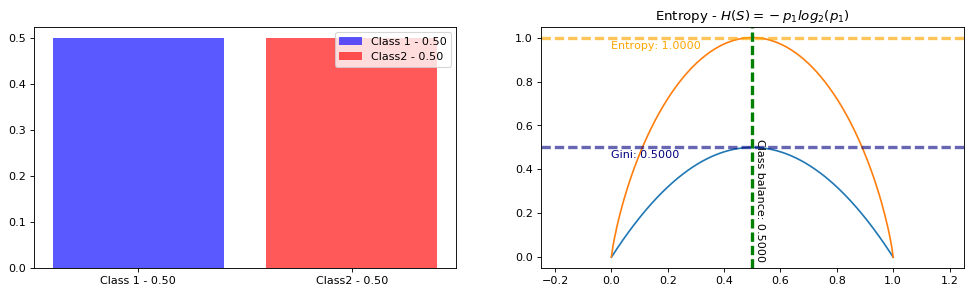

In [45]:
markdown = """


> ## If We're Talking Bacon
>
> {bacons} people, eat bacon<br>
> {fails} people, fail<br>
>
> ### {bacons_pct} / {fails_pct} Class balance [@ some condition] == {balance}


"""

def plot_entropy(p):
    
    positive_class_probability = p
    negative_class_probability = 1 - p
    
    class_probabilities = [positive_class_probability, negative_class_probability]
    class_balance       = 1 - min(class_probabilities)
    entropy_score       = entropy(class_probabilities)
    gini_score          = gini(class_probabilities)
    
    scaled_half = lambda n: int((100 * n) * .5)
    
    display(
        Markdown(
            markdown.format(
                bacons     = scaled_half(positive_class_probability), 
                bacons_pct = positive_class_probability, 
                fails      = scaled_half(negative_class_probability),
                fails_pct  = negative_class_probability, 
                balance    = class_balance
            )
        )
    )
    
    ## generator for log2 entropy
    n_groups  =  2
    index     =  np.arange(n_groups)
    bar_width =  .8
    classes   =  ["Class 1 - %.2f", "Class2 - %.2f"]
    classes   =  [c % class_probabilities[i] for i, c in enumerate(classes)]
    
    f, (class_plot, entropy_plot) = plt.subplots(1, 2, figsize=(15, 4), dpi=80)
    entropy_y, entropy_x  = entropy_generator()
    gini_y, gini_x        = gini_generator()
    
    entropy_plot.plot(gini_x, gini_y)
    entropy_plot.plot(entropy_x, entropy_y)
    entropy_plot.set_title("Entropy - $H(S) = -p_1log_2(p_1)$")
    entropy_plot.set_xlim(-.25, 1.25)
    
    entropy_plot.axvline(x=class_balance, linestyle='dashed', linewidth=3, color="g")
    entropy_plot.text(class_balance + .01, .5, "Class balance: %.4f" % class_balance, rotation=-90)
    
    entropy_plot.axhline(y=entropy_score, linestyle='dashed', linewidth=3, color="orange", alpha=.65)
    entropy_plot.text(.0, entropy_score - .05, "Entropy: %.4f" % entropy_score, color="orange")
    
    entropy_plot.axhline(y=gini_score, linestyle='dashed', linewidth=3, color="navy", alpha=.6)
    entropy_plot.text(.0, gini_score - .05, "Gini: %.4f" % gini_score,  color="navy")
     
    class_plot.bar(0, positive_class_probability, bar_width, color="b", label=classes[0], alpha=.65)
    class_plot.bar(1, negative_class_probability, bar_width, color="r", label=classes[1], alpha=.65)

    class_plot.set_xticks(index)
    class_plot.set_xticklabels(classes)
    class_plot.legend()
                               
    print(positive_class_probability, negative_class_probability, entropy(class_probabilities))

def entropy_generator(granularity = 200):
    """  Proportional class pairs  """
    class_probabilities = np.array(
        [(n, 1-n) for n in np.linspace(0.0001, .999999, granularity)])

    """ Entropy per class pairs"""
    return ([-sum(p * np.log2(p) for p in (class1, class2)) 
            for class1, class2 in class_probabilities], class_probabilities[:, 0])

def gini_generator(granularity=300):
    x = np.linspace(.0001, .99999, granularity)
    return [[gini([n, 1 - n]) for n in x], x]

def class_probabilities(labels): 
    total_count = len(labels) 
    return [count / total_count for count in Counter(labels).values()]

def entropy(class_probabilities):
    
    """given a list of class probabilities, compute the entropy""" 
    return np.sum(
        -p * np.log2(p) 
        for p in class_probabilities
            if p # ignore zero probabilities
    )

def gini(class_probabilities):
    return 1 - np.sum(
        p**2
        for p in class_probabilities
            if p # ignore zero probabilities
    )

# slider  =  FloatSlider(min=-5, max=5, step=0.3, value=0)

balance_slider = widgets.FloatSlider(
    value             =  .5,
    min               =  0,
    max               =  .99,
    step              =  .01,
    description       =  'Class Balance:',
    disabled          =  False,
    continuous_update =  False,
    orientation       =  'horizontal',
    readout           =  True,
    readout_format    =  '.2f',
)

interact(plot_entropy, p=balance_slider)


### (~5 mins) How should we split our data?
Explore this DataFrame and let's discuss some ideas.


In [46]:
bacon = pd.read_csv("bacon.csv")
bacon

,name,tweets_regularly,is_vegan,knows_kungfu,bacon
0,Pepper,1,1,1,0
1,Chuck,0,0,1,1
2,Jane,0,0,1,1
3,Frances,1,1,1,0
4,Yun-yun,0,1,1,1
5,Dr. Bacon,1,0,1,1
6,Mr. Beefsteak,0,0,1,1
7,Macho Commacho,1,0,1,1
8,Pat,1,1,1,0
9,Mrs. Ligeti,0,1,0,0


In [47]:
bacon.groupby(["bacon", "is_vegan", "knows_kungfu", 'tweets_regularly']).size()

bacon  is_vegan  knows_kungfu  tweets_regularly
0      1         0             0                   1
                 1             1                   3
1      0         1             0                   4
                               1                   2
       1         1             0                   1
dtype: int64

### What is the entropy of a subset that is %60 bacon and %40 not bacon?

In [48]:
# A: 

### Find the entropy and Gini of "is_vegan"
Consider making this a function so you can just plug in "is_vegan" and return the entropy score.

In [49]:
# A: 

## Information Gain

## $$ \Delta = H(\text{parent}) - \sum_{\text{children}}\frac{N_j}{N}H(\text{child}_j) $$

$$IG(T,a) = H(T) - H(T|a)$$ 

IG closer to 1 is desirable, unlike Gini or Entropy on its own.  IG is the weighed sum of either Gini or Entropy of all conditions for a node.

$H$ can be Gini or Entropy but we can use this to understand the overall information gain from parent to children.  If we wanted to see the first calculated gain for our first node, we could use the following example (which I know looks like a lot but we'll focus on a few elements to see how we can relate this idea of "best decision").

In [50]:
# A:
conditions = ["is_vegan", "knows_kungfu", "tweets_regularly"]

p_default      = bacon[bacon.bacon==1].bacon.count() * 1.0 / bacon.shape[0]
parent_entropy = entropy([1-p_default, p_default])
parent_gini    = gini([1-p_default, p_default])

print("Parent Entropy is %.2f " % parent_entropy)
print("Parent Gini is %.2f " % parent_gini)

for condition in conditions:
    
    total1       =  bacon[bacon[condition] == 1].shape[0]
    bacon_total1 =  int(bacon[bacon[condition] == 1][['bacon']].sum().values[0])
    bacon_pct1   =  bacon_total1 * 1.0 / total1
    nonbacon_pct1 =  1 - bacon_pct1
    entropy_s1   =  entropy([nonbacon_pct1, bacon_pct1])
    gini_s1      =  gini([nonbacon_pct1, bacon_pct1])
    
    print("Condition: %s == 1" % condition)
    print("Total rows for this condition:     %s" % total1)
    print("Bacon:     %s" % bacon_total1)
    print("Non Bacon: %d" % (total1 - bacon_total1))
    print("Balance:   %.2f/%.2f" % (bacon_pct1, nonbacon_pct1))
    print("Entropy:   %.2f" % entropy_s1)
    print("Gini:   %.2f" % gini_s1)
    print("========== NEXT CONDITION ==============")
    
    total0       =  bacon[bacon[condition] == 0].shape[0]
    bacon_total0 =  int(bacon[bacon[condition] == 0][['bacon']].sum().values[0])
    bacon_pct0   =  bacon_total0 * 1.0 / total0
    nonbacon_pct0=  1 - bacon_pct0
    #print bacon_pct, nonbacon_pct
    entropy_s0   =  entropy([nonbacon_pct0, bacon_pct0])
    gini_s0      =  gini([nonbacon_pct0, bacon_pct0])
    
    print("Condition: %s == 0" % condition)
    print("Total rows for this condition:     %s" % total0)
    print("Bacon:     %s" % bacon_total0)
    print("Non Bacon: %d" % (total0 - bacon_total0))
    print("Balance:   %.2f/%.2f" % (bacon_pct0, nonbacon_pct0))
    print("Entropy:   %.2f" % entropy_s0)
    print("Gini:   %.2f" % gini_s0)
    
    Ig = parent_entropy - (entropy_s1*total1/bacon.shape[0]  + entropy_s0*total0/bacon.shape[0])
    
    print("Information Gain with Entroypy for all conditions at this level is %.2f" % Ig)
    print("=========== NEXT FEATURE =============")


Parent Entropy is 0.95 
Parent Gini is 0.46 
Condition: is_vegan == 1
Total rows for this condition:     5
Bacon:     1
Non Bacon: 4
Balance:   0.20/0.80
Entropy:   0.72
Gini:   0.32
========== NEXT CONDITION ==============
Condition: is_vegan == 0
Total rows for this condition:     6
Bacon:     6
Non Bacon: 0
Balance:   1.00/0.00
Entropy:   0.00
Gini:   0.00
Information Gain with Entroypy for all conditions at this level is 0.62
=========== NEXT FEATURE =============
Condition: knows_kungfu == 1
Total rows for this condition:     10
Bacon:     7
Non Bacon: 3
Balance:   0.70/0.30
Entropy:   0.88
Gini:   0.42
========== NEXT CONDITION ==============
Condition: knows_kungfu == 0
Total rows for this condition:     1
Bacon:     0
Non Bacon: 1
Balance:   0.00/1.00
Entropy:   0.00
Gini:   0.00
Information Gain with Entroypy for all conditions at this level is 0.14
=========== NEXT FEATURE =============
Condition: tweets_regularly == 1
Total rows for this condition:     5
Bacon:     2
Non Bac

### Find the entropy of each condition
> Bonus points: In iteration or by map / apply functions

In [51]:
# bacon.query("is_vegan == 1").groupby("bacon").size()
# bacon.query("knows_kungfu == 1").groupby("bacon").size()
# bacon.query("tweets_regularly == 1").groupby("bacon").size()

In [52]:
# A:

## Let's fit a decision tree and graph it

In [56]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(criterion='gini', min_samples_split=1)
model = tree.fit(bacon[conditions], bacon['bacon'])


## Graphviz can be confusing
We will look at it.  Also check out my annotated figure afterwards.

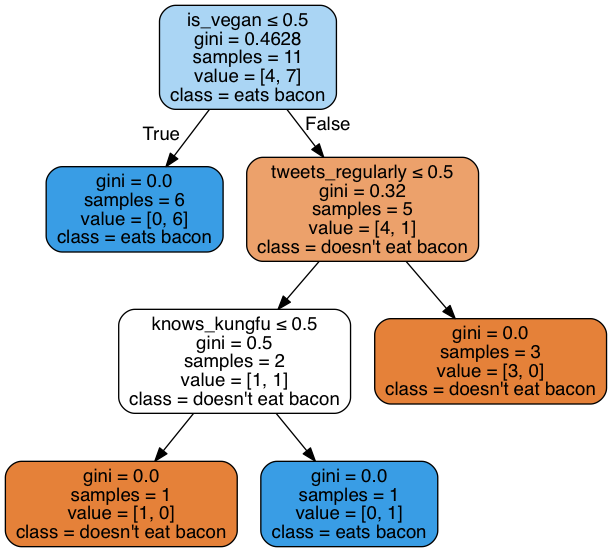

In [58]:
dot_data = StringIO()  

export_graphviz(
    model, 
    out_file = dot_data,  
    filled=True, rounded=True, proportion=False,
    special_characters=True, 
    feature_names=conditions,
    class_names=["doesn't eat bacon", "eats bacon"]
)  

graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  

Image(graph.create_png())  

### There are lots parameters to change the output of the figure
However, here is another way of looking at this:
<img src="https://snag.gy/s0xWe2.jpg" width="600">

In [774]:
# Check some of the probabilities out if you want here
# gini([.36, .64]), gini([.8, .2])

(0.4608, 0.31999999999999984)

In [63]:
# We can look at the data here.  The is_vegan and yes_bacon masks
# are defined a few cells below if you want.
# bacon[is_vegan & ~yes_bacon]

In [709]:
# 1. (is_vegan == 0) & no_bacon = 6
# 2. left (is_vegan == 1) & no_bacon = 4

(11, 5)

## What's happening with our decision tree?

We can validate each step by looking at the various aspects of our data, calculated by the decision tree model, represented by the graph figure.


### Vegans, and their bacon eating habbits
<img src="https://snag.gy/4youaJ.jpg" width="600">

- **Root node**
    - **4** (%36) of **11** total people don't eat bacon.
    - **7** (%64) of **11** total people eat bacon eaters. 
    
    
- **Left node**
    - `is_vegan <= .5` this is basically when `is_vegan == 0`.
    - **6** non-vegans eat bacon
    - Gini score of 0.0, is considered "pure" because the node contains homogenous data that describe non-bacon eating.
    - All observations subset into this node, 6, can be described as `is_vegan == 0` and `bacon == 1` 

In [60]:
# These masks will make it convenient for us to inspect the data manually to verify our graph
is_vegan         = (bacon['is_vegan'] == 1)
tweets_regularly = (bacon['tweets_regularly'] == 1)
yes_bacon        = (bacon['bacon'] == 1)
knows_kungfu     = (bacon['knows_kungfu'] == 1)

# A handy function for finding bacon
def bacon_highlight(row):
    return ["background-color: red" if row[key] == 1 and key == "bacon" else "" 
            for key in row.keys()]

In [1023]:
## Root node, all data
## 4 non bacons, 7 eating bacon
bacon.style.apply(bacon_highlight, axis=1)

,name,tweets_regularly,is_vegan,knows_kungfu,bacon
0,Pepper,1,1,1,0
1,Chuck,0,0,1,1
2,Jane,0,0,1,1
3,Frances,1,1,1,0
4,Yun-yun,0,1,1,1
5,Dr. Bacon,1,0,1,1
6,Mr. Beefsteak,0,0,1,1
7,Macho Commacho,1,0,1,1
8,Pat,1,1,1,0
9,Mrs. Ligeti,0,1,0,0


In [1021]:
## Left Node
## If not vegan, its pretty much unnanimous (in this data at least!), that you eat bacon
bacon[~is_vegan].style.apply(bacon_highlight, axis=1)

,name,tweets_regularly,is_vegan,knows_kungfu,bacon
1,Chuck,0,0,1,1
2,Jane,0,0,1,1
5,Dr. Bacon,1,0,1,1
6,Mr. Beefsteak,0,0,1,1
7,Macho Commacho,1,0,1,1
10,Jackson,0,0,1,1


In [1019]:
## Sent to right node
## vegans, 4 don't eat bacon, 1 does not
bacon[is_vegan].style.apply(bacon_highlight, axis=1)

,name,tweets_regularly,is_vegan,knows_kungfu,bacon
0,Pepper,1,1,1,0
3,Frances,1,1,1,0
4,Yun-yun,0,1,1,1
8,Pat,1,1,1,0
9,Mrs. Ligeti,0,1,0,0


<img src="https://snag.gy/M8ijHq.jpg" width="400">

- When they are vegan
  - **5** of **11** (%45) people are vegan _(samples = 5)_
  - **4** (%80) don't eat bacon, **1** (%20) eats bacon _(value = [4,1])_
  
  
- The right node cooresponds with vegans who tweet reglarly _(tweets__regularly <= .5)_
  - **3** users are vegan and tweet regularly (tweets_regularly =1 )
  - All of these users eat bacon _(samples = 3 and values = [3,0])_
  - **3** / **11** can describe **%27.3** of all users as non-bacon eaters
  - Gini score of 0 = homogenous subset given that all 3 records having bacon = 0, and 0 when bacon = 1
  
  
- The left node cooresponds with vegans who **DONT** tweet reglarly _(tweets__regularly <= .5)_
  - 2 samples 
  - 1 bacon eating, 1 non-bacon
  - Gini locked at .5 - equal class balance


> Note: You can turn proportion=True to show % of class reponses at terminated nodes (predictions)

## What is the probability `p(eating bacon|is_vegan=1)`?
Let's check in.

In [1067]:
## Right node: vegans who tweet, 
bacon[is_vegan & tweets_regularly].style.apply(bacon_highlight, axis=1)

,name,tweets_regularly,is_vegan,knows_kungfu,bacon
0,Pepper,1,1,1,0
3,Frances,1,1,1,0
8,Pat,1,1,1,0


In [1069]:
## Left node: vegans who DONT tweet
bacon[is_vegan & ~tweets_regularly].style.apply(bacon_highlight, axis=1)

,name,tweets_regularly,is_vegan,knows_kungfu,bacon
4,Yun-yun,0,1,1,1
9,Mrs. Ligeti,0,1,0,0


In [65]:
## Vegans who tweet_regularly (they all seem to know kung-fu?)
bacon[is_vegan & tweets_regularly].style.apply(bacon_highlight, axis=1)
## gini = 0 

,name,tweets_regularly,is_vegan,knows_kungfu,bacon
0,Pepper,1,1,1,0
3,Frances,1,1,1,0
8,Pat,1,1,1,0


In [64]:
# Recall all vegans, there is 1 eating the bacon.  If we look at tweets.
bacon[is_vegan].style.apply(bacon_highlight, axis=1)
# gini([.36, 1 - .36])

,name,tweets_regularly,is_vegan,knows_kungfu,bacon
0,Pepper,1,1,1,0
3,Frances,1,1,1,0
4,Yun-yun,0,1,1,1
8,Pat,1,1,1,0
9,Mrs. Ligeti,0,1,0,0


In [1061]:
bacon[is_vegan & ~tweets_regularly].style.apply(bacon_highlight, axis=1)

# gini = .5

,name,tweets_regularly,is_vegan,knows_kungfu,bacon
4,Yun-yun,0,1,1,1
9,Mrs. Ligeti,0,1,0,0


## What do you think would happen if:
_Knowing what you know now._

- We qualified how many records in a subset where allowed to be a child node?
- Removed child nodes based on some quality metric?
- Set the max depth that a tree was allowed to become?
- What if we let our tree grow to max depth?

<a id='overfit'></a>
## Addressing overfitting

---

A stopping criterion determines when to no longer construct further nodes. 

We can stop when all records belong to the same class, or when all records have the same attributes. This *maximizes variance at the expense of bias*, leading to overfitting. 

**Setting a maximum depth:**

A simple way to prevent overfitting is to set a hard limit on the "depth" of the decision tree.

**Minimum observations to make a split:**

An alternative to maximum depth (and can be used at the same time), is to specify the minimum number of datapoints reqired to make a split at a node.


<a id='advantages'></a>
## CART advantages
---

- Simple to understand and interpret. People are able to understand decision tree models after a brief explanation.
    - Useful to work with non technical departments (marketing/sales).
- Requires little data preparation. 
    - Other techniques often require data normalization, dummy variables need to be created and blank values to be removed.
- Able to handle both numerical and categorical data. 
    - Other techniques are usually specialized in analyzing datasets that have only one type of variable.
- Uses a **white box** model.
    - If a given situation is observable in a model the explanation for the condition is easily explained by boolean logic.
    - By contrast, in a **black box** model, the explanation for the results is typically difficult to understand, for example in neural networks.
- Possible to validate a model using statistical tests. That makes it possible to account for the reliability of the model.
- Robust. Performs well even if its assumptions are somewhat violated by the true model from which the data were generated.
- Performs well with large datasets. Large amounts of data can be analyzed using standard computing resources in reasonable time.
- Once trained can be implemented on hardware and has extremely fast execution.
    - Real-time applications like trading, for example.

<a id='disadvantages'></a>
## CART disadvantages
---

- Locally-optimal.
    - Practical decision-tree learning algorithms are based on heuristics such as the greedy algorithm where locally-optimal decisions are made at each node. 
    - Such algorithms cannot guarantee to return the globally-optimal decision tree.
- Overfitting.
    - Decision-tree learners can create over-complex trees that do not generalize well from the training data.
- There are concepts that are hard to learn because decision trees do not express them easily, such as XOR, parity or multiplexer problems. In such cases, the decision tree becomes prohibitively large.
    - Neural networks, for example, are superior for these problems.
- Decision tree learners create biased trees if some classes dominate. It is therefore recommended to balance the dataset prior to fitting with the decision tree.